# Chapter 4 — model and biology figures

Builds every model-performance, confound and interpretability figure and table for the
MIL age-score chapter from the CSV files written by the review tasks
(`outputs/review/task1 … task6`). No model is trained or loaded here, so the notebook
runs in seconds and every number in the chapter can be regenerated from it.

| Section | Figure / table | Source |
|---|---|---|
| 1 | Model selection audit, training curves | task1 `epochs_*.csv`, `selected_epochs.csv` |
| 2 | Held-out trajectories (headline figure) | task1 `bag_predictions.csv` |
| 3 | Alignment of the score scale | task1 `bag_predictions.csv` |
| 4 | Pooling, feature-block and linear baselines | task3 |
| 5 | Feature-subset runs | task6 |
| 6 | Late-passage behaviour and score quantisation | task1, task4 `well_scores.csv` |
| 7 | Confound diagnostics | task4 |
| 8 | Attention and feature attribution | legacy `explain.py` outputs, task3 ridge coefficients |

Set `REPO` below to the root of the MILAgeScore repository.

In [1]:
from pathlib import Path
import json, re, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, kendalltau, mannwhitneyu

warnings.filterwarnings("ignore", category=FutureWarning)

# ── paths ────────────────────────────────────────────────────────────────────
REPO    = Path(".")                              # root of the MILAgeScore repo
REVIEW  = REPO / "outputs" / "review"            # task1 … task6 folders
LEGACY  = REVIEW / "legacy"                      # explain.py outputs of the earlier LOCO runs
                                                 # (loco_binned_HO_L*_*.csv, attention_concentration.csv)
PROC    = REPO / "data" / "processed"            # only needed for the optional cells in section 8
FIG_DIR = REPO / "thesis_figures" / "chapter4"
TAB_DIR = REPO / "thesis_tables" / "chapter4"
FIG_DIR.mkdir(parents=True, exist_ok=True); TAB_DIR.mkdir(parents=True, exist_ok=True)

# ── experiment constants ─────────────────────────────────────────────────────
P_MIN, P_MAX = 4, {1: 15, 2: 18}                 # first passage; passage at growth arrest
N_BINS       = 10
OVERLAP      = (4, 15)                           # passages present in both lines
SEEDS        = [0, 1, 2]

# ── plotting style ───────────────────────────────────────────────────────────
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9, "legend.fontsize": 8,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.spines.top": False,
    "axes.spines.right": False, "legend.frameon": False, "pdf.fonttype": 42,
})
C_LINE  = {1: "#1b6ca8", 2: "#d1495b"}           # line 1, line 2
C_BLOCK = {"shape": "#d1495b", "intensity": "#2e8b57", "ratio": "#8e6bbf",
           "texture-distribution": "#e08e0b", "latent": "#1b6ca8"}

def savefig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}")
    print(f"saved {FIG_DIR / name}.png/.pdf")

def savetab(df, name, **kw):
    df.to_csv(TAB_DIR / f"{name}.csv", **kw)
    print(f"saved {TAB_DIR / name}.csv")

## Label definitions

The same definitions as `prepare_data.py` and `binning.py`, kept in one place so that every
reference target in this notebook is derived from the passage number and nothing else.

In [2]:
def s_frac(line, p):
    """Unbinned fraction of replicative lifespan, s = (p - p_min) / (p_arrest - p_min)."""
    return (np.asarray(p, float) - P_MIN) / (P_MAX[int(line)] - P_MIN)

def s_bin(line, p, n_bins=N_BINS):
    """Binned label used for training: equal-width bins on s, mapped to bin / (n_bins - 1)."""
    s = s_frac(line, p)
    edges = np.linspace(0, 1, n_bins + 1)
    return np.clip(np.digitize(s, edges[1:-1]), 0, n_bins - 1) / (n_bins - 1)

def targets(held_out, p):
    """Reference targets for a held-out line at passage p (arrays).
    own_bin   : the held-out line's own binned label
    own_frac  : the held-out line's own unbinned lifespan fraction
    same_pass : the TRAINING line's binned label at the same passage number
    to_arrest : the TRAINING line's binned label at the same number of passages before arrest
    """
    p = np.asarray(p, float); train = 3 - int(held_out)
    out = {"own_bin": s_bin(held_out, p), "own_frac": s_frac(held_out, p)}
    ok = (p >= P_MIN) & (p <= P_MAX[train])
    out["same_pass"] = np.where(ok, s_bin(train, np.clip(p, P_MIN, P_MAX[train])), np.nan)
    q = p - (P_MAX[int(held_out)] - P_MAX[train])
    ok = (q >= P_MIN) & (q <= P_MAX[train])
    out["to_arrest"] = np.where(ok, s_bin(train, np.clip(q, P_MIN, P_MAX[train])), np.nan)
    return out

TARGET_LABEL = {"own_bin": "own binned label", "own_frac": "own lifespan fraction",
                "same_pass": "same passage number", "to_arrest": "passages before arrest"}

label_grid = pd.DataFrame(
    [(l, p, s_frac(l, p).round(3), int(round(float(s_bin(l, p)) * (N_BINS - 1))))
     for l in (1, 2) for p in range(P_MIN, P_MAX[l] + 1)],
    columns=["line", "passage", "s", "bin"])
label_grid.pivot(index="passage", columns="line", values="bin")

line,1,2
passage,,
4,0.0,0.0
5,0.0,0.0
6,1.0,1.0
7,2.0,2.0
8,3.0,2.0
9,4.0,3.0
10,5.0,4.0
11,6.0,5.0
12,7.0,5.0


## Loading predictions

Every task wrote a `bag_predictions.csv` with one row per scored bag. They are stacked into one
long table with a `config` column naming the model variant. Only held-out-line bags are kept.

In [3]:
def _held(df):
    df = df.copy()
    df["cell_line"] = pd.to_numeric(df["cell_line"], errors="coerce")
    if "set" in df.columns:
        df = df[df["set"].astype(str).eq("heldout")]
    else:                                           # ridge file: all rows are held-out bags
        df["cell_line"] = df["held_out_line"]
    return df[df["cell_line"] == df["held_out_line"]]

def load_predictions():
    parts = []
    t1 = _held(pd.read_csv(REVIEW / "task1" / "bag_predictions.csv"))
    t1["config"] = "MIL attention, all features"; t1["family"] = "main"
    parts.append(t1)

    f3 = REVIEW / "task3" / "bag_predictions.csv"
    if f3.exists():
        t3 = _held(pd.read_csv(f3))
        t3 = t3[t3["model"].eq("mil") & ~t3["run_id"].isin(t1["run_id"].unique())]
        name = {("mean", "both"): "MIL mean pooling, all features",
                ("attention", "manual"): "MIL attention, manual only",
                ("attention", "latent"): "MIL attention, latent only"}
        t3["config"] = [name.get((a, b), f"MIL {a}, {b}") for a, b in zip(t3["pooling"], t3["feature_set"])]
        t3["family"] = "baseline"; parts.append(t3)
    fr = REVIEW / "task3" / "bag_predictions_ridge.csv"
    if fr.exists():
        r = _held(pd.read_csv(fr))
        r["config"] = np.where(r["run_id"].str.contains("meanstd"), "Ridge, bag mean + SD", "Ridge, bag mean")
        r["family"] = "baseline"; parts.append(r)

    f6 = REVIEW / "task6" / "bag_predictions.csv"
    if f6.exists():
        t6 = _held(pd.read_csv(f6))
        sub = t6["run_id"].str.extract(r"_s\d+_(.+)$")[0]          # the feature_subset column is unreliable
        t6["config"] = sub.map({"session_robust": "MIL attention, session-robust features",
                                "session_sensitive": "MIL attention, session-sensitive features",
                                "shape_latent": "MIL attention, shape + latent features"})
        t6["family"] = "subset"; parts.append(t6)

    keep = ["config", "family", "run_id", "seed", "train_line", "held_out_line", "passage_raw", "s_hat"]
    df = pd.concat([p[keep] for p in parts], ignore_index=True)
    return df.astype({"seed": int, "held_out_line": int, "passage_raw": int})

pred = load_predictions()
pred.groupby(["family", "config", "held_out_line"]).agg(runs=("run_id", "nunique"), bags=("s_hat", "size"))

FileNotFoundError: [Errno 2] No such file or directory: 'outputs\\review\\task1\\bag_predictions.csv'

## Metrics

All metrics are computed at **group level**: the 30 bag scores of a (line, passage) group are
averaged first, and the metric is taken over the passage means. Rank correlation is against passage
number. Errors are reported against four reference targets (see `targets`). Unless stated, the
passage range is P4–P15, the range both lines share. Values are mean ± SD over the three seeds.

In [4]:
def group_means(df):
    return (df.groupby(["config", "family", "held_out_line", "seed", "passage_raw"], as_index=False)
              .agg(s_hat=("s_hat", "mean"), s_sd=("s_hat", "std"),
                   q05=("s_hat", lambda x: np.percentile(x, 5)), q95=("s_hat", lambda x: np.percentile(x, 95))))

def run_metrics(g, lo=OVERLAP[0], hi=OVERLAP[1]):
    """g: group means of ONE run (one config, one held-out line, one seed)."""
    ho = int(g["held_out_line"].iloc[0]); g = g.sort_values("passage_raw")
    full = g.set_index("passage_raw")["s_hat"]
    m = g[(g.passage_raw >= lo) & (g.passage_raw <= hi)]
    p, s = m["passage_raw"].to_numpy(), m["s_hat"].to_numpy()
    T = targets(ho, p)
    out = {"rho": spearmanr(p, s)[0], "tau": kendalltau(p, s)[0],
           "n_decreases": int((np.diff(s) < 0).sum())}
    for k, t in T.items():
        ok = np.isfinite(t)
        out[f"mae_{k}"]  = np.abs(s[ok] - t[ok]).mean()
        out[f"bias_{k}"] = (s[ok] - t[ok]).mean()
    out["s_first"], out["s_P15"] = s[0], full.get(15, np.nan)
    if ho == 2 and 16 in full.index:                       # passages beyond the training range
        late = np.array([16, 17, 18])
        out["late_bias"] = (full.loc[late].to_numpy() - s_bin(2, late)).mean()
        out["drop_15_16"] = full[15] - full[16]
        out["s_P18"] = full[18]
    return pd.Series(out)

gm  = group_means(pred)
KEYS = ["family", "config", "held_out_line", "seed"]
per_run = pd.DataFrame([{**dict(zip(KEYS, k)), **run_metrics(g).to_dict()}      # explicit loop: works on pandas 1.x-3.x
                        for k, g in gm.groupby(KEYS)])

def summarise(per_run, cols):
    g = per_run.groupby(["family", "config", "held_out_line"])[cols]
    return g.mean().join(g.std(), rsuffix="_sd")

MAIN_COLS = ["rho", "mae_own_bin", "mae_own_frac", "mae_same_pass", "mae_to_arrest",
             "bias_own_bin", "bias_same_pass", "s_P15", "late_bias", "drop_15_16", "s_P18"]
summary = summarise(per_run, MAIN_COLS)
savetab(per_run, "metrics_per_run", index=False)
savetab(summary.reset_index(), "metrics_summary", index=False)
summary[MAIN_COLS].round(3)

saved thesis_tables/chapter4/metrics_per_run.csv
saved thesis_tables/chapter4/metrics_summary.csv


/tmp/ipykernel_4861/3556747127.py:34: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  return g.mean().join(g.std(), rsuffix="_sd")


rho  \
family   config                                    held_out_line          
baseline MIL attention, latent only                1              0.897   
                                                   2              0.737   
         MIL attention, manual only                1              0.998   
                                                   2              0.995   
         MIL mean pooling, all features            1              0.981   
                                                   2              0.993   
         Ridge, bag mean                           1              0.956   
                                                   2              0.988   
         Ridge, bag mean + SD                      1              0.965   
                                                   2              0.991   
main     MIL attention, all features               1              0.984   
                                                   2              0.998   
subset   MIL attention, session-robust features    1              0.951   
                                                   2              0.972   
         MIL attention, session-sensitive features 1              0.984   
                                                   2              0.995   
         MIL attention, shape + latent features    1              0.911   
                                                   2              0.946   

                                                                  mae_own_bin  \
family   config                                    held_out_line                
baseline MIL attention, latent only                1                    0.162   
                                                   2                    0.141   
         MIL attention, manual only                1                    0.099   
                                                   2                    0.096   
         MIL mean pooling, all features            1                    0.104   
                                                   2                    0.086   
         Ridge, bag mean                           1                    0.093   
                                                   2                    0.054   
         Ridge, bag mean + SD                      1                    0.106   
                                                   2                    0.050   
main     MIL attention, all features               1                    0.102   
                                                   2                    0.085   
subset   MIL attention, session-robust features    1                    0.130   
                                                   2                    0.073   
         MIL attention, session-sensitive features 1                    0.116   
                                                   2                    0.062   
         MIL attention, shape + latent features    1                    0.133   
                                                   2                    0.106   

                                                                  mae_own_frac  \
family   config                                    held_out_line                 
baseline MIL attention, latent only                1                     0.136   
                                                   2                     0.120   
         MIL attention, manual only                1                     0.078   
                                                   2                     0.108   
         MIL mean pooling, all features            1                     0.078   
                                                   2                     0.099   
         Ridge, bag mean                           1                     0.059   
                                                   2                     0.053   
         Ridge, bag mean + SD                      1                     0.065   
                                            

# 1 · Model selection audit

Checkpoint selection, the learning-rate schedule and early stopping all monitored the
inner-validation rank MAE (wells of the *training* line that were never trained on). The held-out
line was scored every epoch but never used. The table shows what that honesty costs: the error at
the selected epoch against the best error that could have been obtained by peeking.

In [5]:
sel = pd.read_csv(REVIEW / "task1" / "selected_epochs.csv")
rows = []
for rid in sel["run_id"]:
    e = pd.read_csv(REVIEW / "task1" / f"epochs_{rid}.csv")
    b = e.loc[e["epoch"] == int(sel.set_index("run_id").loc[rid, "best_epoch"])].iloc[0]
    rows.append({"run_id": rid, "epochs_run": len(e), "train_rank_mae": b.train_mae,
                 "innerval_rank_mae": b.innerval_mae, "heldout_rho_bag": b.heldout_spearman})
sel = sel.merge(pd.DataFrame(rows), on="run_id")
sel["innerval_mae_s"] = sel["innerval_rank_mae"] / (N_BINS - 1)       # within-line error, score units
sel["optimism"] = sel["heldout_mae_s_at_best"] - sel["heldout_mae_s_min_over_epochs"]
sel["held_out_line"] = sel["run_id"].str.extract(r"HO_L(\d)")[0].astype(int)
savetab(sel, "selection_audit", index=False)
sel.round(3)

saved thesis_tables/chapter4/selection_audit.csv


,run_id,best_epoch,stop_epoch,heldout_mae_s_at_best,heldout_mae_s_min_over_epochs,heldout_mae_s_at_last,epochs_run,train_rank_mae,innerval_rank_mae,heldout_rho_bag,innerval_mae_s,optimism,held_out_line
0,loco_HO_L1_seed0,5,20,0.102,0.085,0.093,20,0.071,0.153,0.957,0.017,0.017,1
1,loco_HO_L1_seed1,36,51,0.090,0.078,0.080,51,0.000,0.203,0.960,0.023,0.012,1
2,loco_HO_L1_seed2,7,22,0.090,0.081,0.083,22,0.030,0.250,0.975,0.028,0.009,1
3,loco_HO_L2_seed0,13,28,0.106,0.097,0.117,28,0.007,0.537,0.882,0.060,0.010,2
4,loco_HO_L2_seed1,16,31,0.094,0.086,0.097,31,0.008,0.340,0.923,0.038,0.008,2
5,loco_HO_L2_seed2,36,51,0.115,0.096,0.106,51,0.003,0.383,0.868,0.043,0.020,2


saved thesis_figures/chapter4/M7_training_curves.png/.pdf


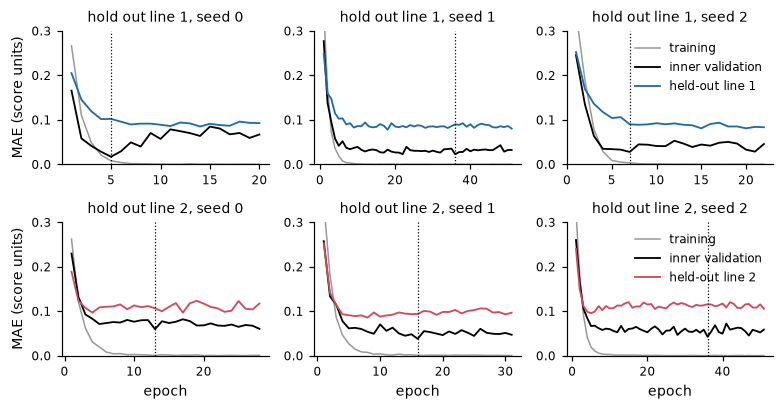

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(7.2, 3.8), sharex=False)
for i, (ho, grp) in enumerate(sel.groupby("held_out_line")):
    for j, rid in enumerate(grp["run_id"]):
        e = pd.read_csv(REVIEW / "task1" / f"epochs_{rid}.csv"); ax = axes[i, j]
        ax.plot(e.epoch, e.train_mae / (N_BINS - 1), color="0.6", lw=1, label="training")
        ax.plot(e.epoch, e.innerval_mae / (N_BINS - 1), color="k", lw=1.2, label="inner validation")
        ax.plot(e.epoch, e.heldout_mae_s, color=C_LINE[ho], lw=1.2, label=f"held-out line {ho}")
        be = int(grp.set_index("run_id").loc[rid, "best_epoch"])
        ax.axvline(be, color="k", ls=":", lw=0.8)
        ax.set_title(f"hold out line {ho}, seed {j}"); ax.set_ylim(0, 0.3)
        if j == 0: ax.set_ylabel("MAE (score units)")
        if i == 1: ax.set_xlabel("epoch")
    axes[i, 2].legend(loc="upper right")
fig.tight_layout(); savefig(fig, "M7_training_curves")

# 2 · Held-out trajectories (headline figure)

Mean bag score per passage for the line the model never saw. Thin lines are individual seeds, the
thick line is the seed mean and the band is the 5–95 % range of bag scores. Three references are
overlaid: the held-out line's own binned label, its unbinned lifespan fraction, and the label the
*training* line carries at the same passage number.

saved thesis_figures/chapter4/M1_heldout_trajectories.png/.pdf


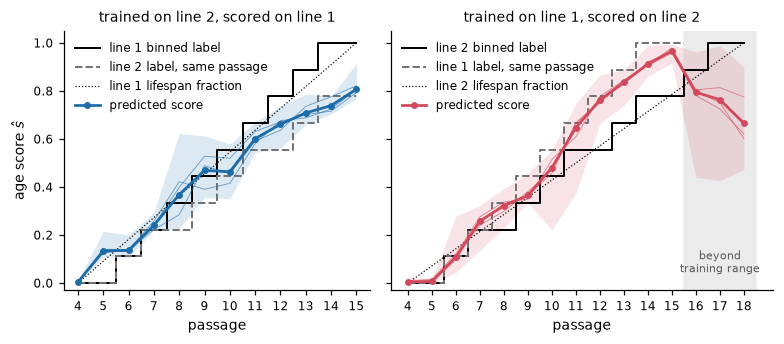

In [7]:
def plot_trajectory(ax, gm, config, ho, refs=("own_bin", "same_pass", "own_frac"), legend=True):
    g = gm[(gm.config == config) & (gm.held_out_line == ho)]
    piv = g.pivot(index="passage_raw", columns="seed", values="s_hat")
    p = piv.index.to_numpy(); T = targets(ho, p)
    style = {"own_bin": dict(color="k", lw=1.3, drawstyle="steps-mid"),
             "same_pass": dict(color="0.45", lw=1.3, ls="--", drawstyle="steps-mid"),
             "own_frac": dict(color="k", lw=0.8, ls=":"),
             "to_arrest": dict(color="0.6", lw=1.0, ls="-.", drawstyle="steps-mid")}
    names = {"own_bin": f"line {ho} binned label", "same_pass": f"line {3-ho} label, same passage",
             "own_frac": f"line {ho} lifespan fraction", "to_arrest": f"line {3-ho} label, passages before arrest"}
    for r in refs:
        ax.plot(p, T[r], label=names[r], **style[r])
    lo = g.groupby("passage_raw")["q05"].min(); hi = g.groupby("passage_raw")["q95"].max()
    ax.fill_between(p, lo.to_numpy(), hi.to_numpy(), color=C_LINE[ho], alpha=0.15, lw=0)
    for s in piv.columns:
        ax.plot(p, piv[s], color=C_LINE[ho], lw=0.6, alpha=0.6)
    ax.plot(p, piv.mean(axis=1), color=C_LINE[ho], lw=1.8, marker="o", ms=3.5, label="predicted score")
    if ho == 2:
        ax.axvspan(15.5, 18.5, color="0.92", zorder=0)
        ax.text(17, 0.03, "beyond\ntraining range", ha="center", va="bottom", fontsize=7, color="0.35")
    ax.set_xticks(p); ax.set_ylim(-0.03, 1.05); ax.set_xlabel("passage")
    if legend: ax.legend(loc="upper left")

MAIN = "MIL attention, all features"
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2), sharey=True, gridspec_kw={"width_ratios": [12, 15]})
for ax, ho in zip(axes, (1, 2)):
    plot_trajectory(ax, gm, MAIN, ho)
    ax.set_title(f"trained on line {3-ho}, scored on line {ho}")
axes[0].set_ylabel(r"age score $\hat{s}$")
fig.tight_layout(); savefig(fig, "M1_heldout_trajectories")

In [8]:
traj = (gm[gm.config == MAIN].groupby(["held_out_line", "passage_raw"])
          .agg(s_hat=("s_hat", "mean"), sd_seeds=("s_hat", "std"), sd_bags=("s_sd", "mean")).reset_index())
for k in TARGET_LABEL:
    traj[k] = [float(targets(h, [p])[k][0]) for h, p in zip(traj.held_out_line, traj.passage_raw)]
savetab(traj.round(4), "heldout_trajectory_main", index=False)
traj.round(3)

saved thesis_tables/chapter4/heldout_trajectory_main.csv


,held_out_line,passage_raw,s_hat,sd_seeds,sd_bags,own_bin,own_frac,same_pass,to_arrest
0,1,4,0.004,0.004,0.002,0.000,0.000,0.000,0.222
1,1,5,0.134,0.009,0.021,0.000,0.091,0.000,0.222
2,1,6,0.136,0.005,0.023,0.111,0.182,0.111,0.333
3,1,7,0.241,0.018,0.012,0.222,0.273,0.222,0.444
4,1,8,0.368,0.074,0.091,0.333,0.364,0.222,0.556
5,1,9,0.469,0.071,0.051,0.444,0.455,0.333,0.556
6,1,10,0.463,0.053,0.032,0.556,0.545,0.444,0.667
7,1,11,0.601,0.027,0.032,0.667,0.636,0.556,0.778
8,1,12,0.661,0.022,0.043,0.778,0.727,0.556,0.778
9,1,13,0.708,0.025,0.019,0.889,0.818,0.667,0.889


# 3 · Which scale does the score follow?

The two lines arrest at different passages, so the same passage number carries a different label
in each line. A score that transferred the *lifespan* scale would sit closest to the held-out
line's own label. A score that follows *passage number* would sit closest to the training line's
label at the same passage. Aligning by passages before arrest is the third possibility.

saved thesis_figures/chapter4/M2_alignment_error.png/.pdf
saved thesis_tables/chapter4/alignment_main.csv


held_out_line,1,2
rho,0.984,0.998
rho_sd,0.004,0.004
mae_own_bin,0.102,0.085
mae_own_bin_sd,0.009,0.005
mae_own_frac,0.075,0.097
mae_own_frac_sd,0.005,0.003
mae_same_pass,0.064,0.036
mae_same_pass_sd,0.013,0.001
mae_to_arrest,0.176,0.271
mae_to_arrest_sd,0.010,0.005


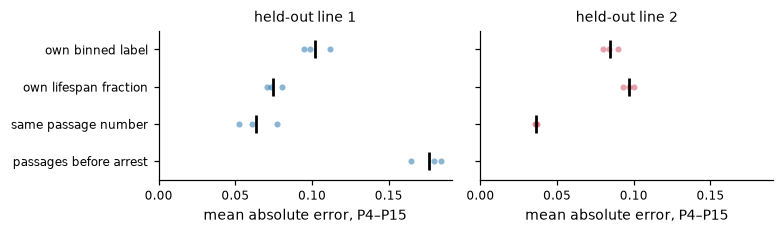

In [9]:
def dot_panel(ax, per_run, configs, col, ho, xlabel=None, ref=None):
    for i, c in enumerate(configs):
        v = per_run[(per_run.config == c) & (per_run.held_out_line == ho)][col].to_numpy()
        ax.plot(v, np.full(len(v), i), "o", ms=3.5, color=C_LINE[ho], alpha=0.45, mec="none")
        ax.plot([v.mean()], [i], "|", ms=11, mew=1.8, color="k")
    ax.set_yticks(range(len(configs))); ax.set_ylim(len(configs) - 0.5, -0.5)
    if ref is not None: ax.axvline(ref, color="0.7", lw=0.8, zorder=0)
    if xlabel: ax.set_xlabel(xlabel)

keys = ["mae_own_bin", "mae_own_frac", "mae_same_pass", "mae_to_arrest"]
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.2), sharex=True, sharey=True)
for ax, ho in zip(axes, (1, 2)):
    m = per_run[(per_run.config == MAIN) & (per_run.held_out_line == ho)]
    for i, k in enumerate(keys):
        ax.plot(m[k], np.full(len(m), i), "o", ms=4, color=C_LINE[ho], alpha=0.5, mec="none")
        ax.plot([m[k].mean()], [i], "|", ms=12, mew=1.8, color="k")
    ax.set_yticks(range(len(keys))); ax.set_yticklabels([TARGET_LABEL[k.replace("mae_", "")] for k in keys])
    ax.set_ylim(len(keys) - 0.5, -0.5); ax.set_xlim(0, None)
    ax.set_xlabel("mean absolute error, P4–P15"); ax.set_title(f"held-out line {ho}")
fig.tight_layout(); savefig(fig, "M2_alignment_error")

align = summary.loc[("main", MAIN)][["rho", "rho_sd"] + [c for k in keys for c in (k, k + "_sd")]
                                   + ["bias_own_bin", "bias_same_pass", "s_P15", "late_bias", "drop_15_16"]]
savetab(align.reset_index(), "alignment_main", index=False)
align.round(3).T

# 4 · Baselines: pooling, feature block and a linear model

Same wells, same inner-validation protocol and same seeds as the main model.
*Ridge* is a linear regression on per-bag feature averages (optionally with per-feature SD).

saved thesis_figures/chapter4/M6a_baselines.png/.pdf
saved thesis_tables/chapter4/baselines_summary.csv


rho  mae_own_bin  \
held_out_line config                                               
1             MIL attention, all features     0.984        0.102   
              MIL mean pooling, all features  0.981        0.104   
              MIL attention, manual only      0.998        0.099   
              MIL attention, latent only      0.897        0.162   
              Ridge, bag mean                 0.956        0.093   
              Ridge, bag mean + SD            0.965        0.106   
2             MIL attention, all features     0.998        0.085   
              MIL mean pooling, all features  0.993        0.086   
              MIL attention, manual only      0.995        0.096   
              MIL attention, latent only      0.737        0.141   
              Ridge, bag mean                 0.988        0.054   
              Ridge, bag mean + SD            0.991        0.050   

                                              mae_own_frac  mae_same_pass  \
held_out_line config                                                        
1             MIL attention, all features            0.075          0.064   
              MIL mean pooling, all features         0.078          0.056   
              MIL attention, manual only             0.078          0.052   
              MIL attention, latent only             0.136          0.184   
              Ridge, bag mean                        0.059          0.108   
              Ridge, bag mean + SD                   0.065          0.087   
2             MIL attention, all features            0.097          0.036   
              MIL mean pooling, all features         0.099          0.039   
              MIL attention, manual only             0.108          0.034   
              MIL attention, latent only             0.120          0.227   
              Ridge, bag mean                        0.053          0.114   
              Ridge, bag mean + SD                   0.052          0.101   

                                              bias_own_bin  bias_same_pass  \
held_out_line config                                                         
1             MIL attention, all features           -0.056           0.055   
              MIL mean pooling, all features        -0.064           0.047   
              MIL attention, manual only            -0.068           0.043   
              MIL attention, latent only             0.068           0.179   
              Ridge, bag mean                       -0.013           0.098   
              Ridge, bag mean + SD                  -0.029           0.082   
2             MIL attention, all features            0.084          -0.027   
              MIL mean pooling, all features         0.085          -0.026   
              MIL attention, manual only             0.095          -0.017   
              MIL attention, latent only             0.011          -0.100   
              Ridge, bag mean                        0.012          -0.099   
              Ridge, bag mean + SD                   0.029          -0.083   

                                              s_P15  s_P18  
held_out_line config                                        
1             MIL attention, all features     0.807    NaN  
              MIL mean pooling, all features  0.795    NaN  
              MIL attention, manual only      0.777    NaN  
              MIL attention, latent only      0.866    NaN  
              Ridge, bag mean                 0.997    NaN  
              Ridge, bag mean + SD            0.960    NaN  
2             MIL attention, all features     0.966  0.665  
              MIL mean pooling, all features  0.961  0.708  
              MIL attention, manual only      0.980  0.727  
              MIL attention, latent only      0.564  0.804  
              Ridge, bag mean                 0.845  0.956  
              Ridge, bag mean + SD            0.877  0.816

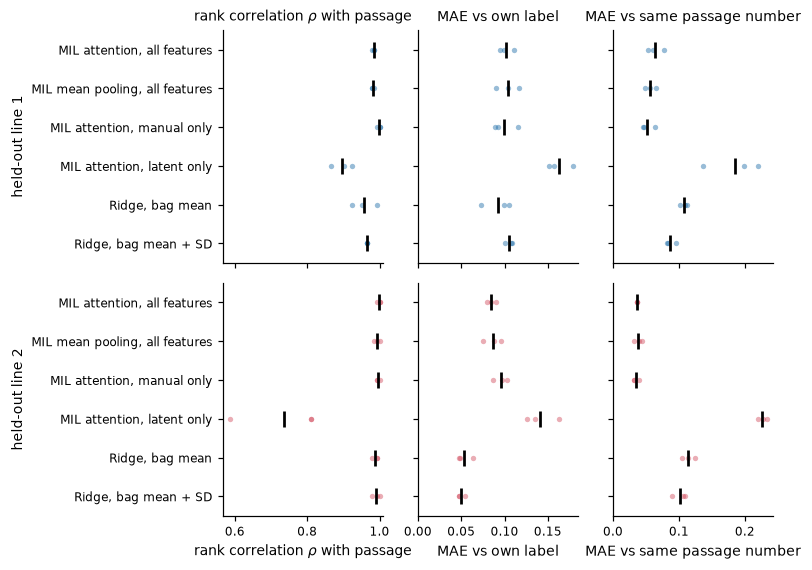

In [10]:
BASE = [MAIN, "MIL mean pooling, all features", "MIL attention, manual only",
        "MIL attention, latent only", "Ridge, bag mean", "Ridge, bag mean + SD"]
BASE = [c for c in BASE if c in set(per_run.config)]

def comparison_figure(per_run, configs, name, short=None):
    cols = [("rho", r"rank correlation $\rho$ with passage"), ("mae_own_bin", "MAE vs own label"),
            ("mae_same_pass", "MAE vs same passage number")]
    fig, axes = plt.subplots(2, 3, figsize=(7.2, 0.33 * len(configs) * 2 + 1.3), sharey=True, sharex="col")
    for i, ho in enumerate((1, 2)):
        for j, (c, lab) in enumerate(cols):
            dot_panel(axes[i, j], per_run, configs, c, ho, xlabel=lab if i == 1 else None)
            if i == 0: axes[i, j].set_title(lab)
        axes[i, 0].set_yticklabels(short or configs)
        axes[i, 0].set_ylabel(f"held-out line {ho}")
    axes[0, 0].set_xlim(None, 1.01)
    for ax in axes[:, 1:].ravel(): ax.set_xlim(0, None)
    fig.tight_layout(); savefig(fig, name); return fig

comparison_figure(per_run, BASE, "M6a_baselines")
tab = summary.reset_index(); tab = tab[tab.config.isin(BASE)]
savetab(tab, "baselines_summary", index=False)
(tab.set_index(["held_out_line", "config"])
    [["rho", "mae_own_bin", "mae_own_frac", "mae_same_pass", "bias_own_bin", "bias_same_pass", "s_P15", "s_P18"]]
    .loc[[(h, c) for h in (1, 2) for c in BASE]].round(3))

saved thesis_figures/chapter4/M6b_linear_vs_neural_trajectories.png/.pdf


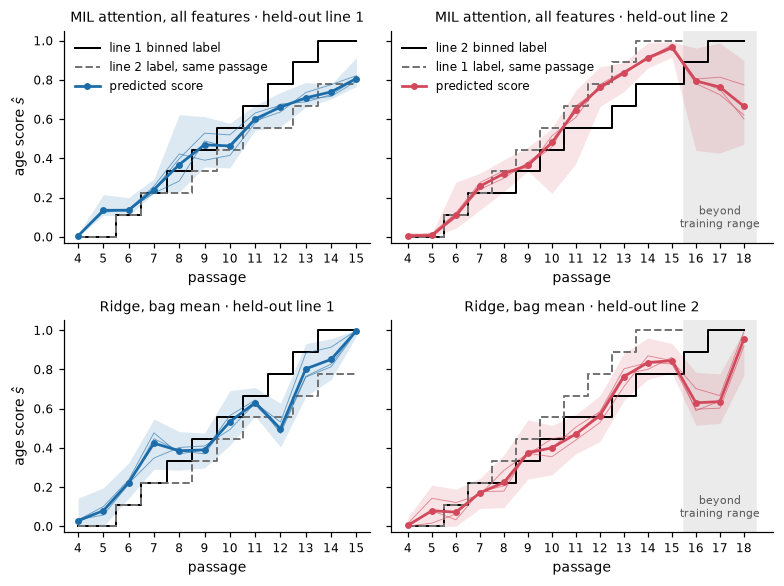

In [11]:
# Trajectories of the linear baseline next to the neural model
cfgs = [c for c in (MAIN, "Ridge, bag mean") if c in BASE]
fig, axes = plt.subplots(len(cfgs), 2, figsize=(7.2, 2.7 * len(cfgs)), sharey=True, squeeze=False,
                         gridspec_kw={"width_ratios": [12, 15]})
for i, c in enumerate(cfgs):
    for j, ho in enumerate((1, 2)):
        plot_trajectory(axes[i, j], gm, c, ho, refs=("own_bin", "same_pass"), legend=(i == 0))
        axes[i, j].set_title(f"{c} · held-out line {ho}")
    axes[i, 0].set_ylabel(r"age score $\hat{s}$")
fig.tight_layout(); savefig(fig, "M6b_linear_vs_neural_trajectories")

# 5 · Feature-subset runs

*Session-robust* features are those whose passage-to-passage fluctuations are not shared between
the two lines (section 7); *session-sensitive* is the complement; *shape + latent* drops every
intensity, ratio and texture feature.

saved thesis_figures/chapter4/M6c_feature_subsets.png/.pdf
saved thesis_tables/chapter4/feature_subsets_summary.csv


rho  mae_own_bin  \
held_out_line config                                                          
1             MIL attention, all features                0.984        0.102   
              MIL attention, session-robust features     0.951        0.130   
              MIL attention, session-sensitive features  0.984        0.116   
              MIL attention, shape + latent features     0.911        0.133   
2             MIL attention, all features                0.998        0.085   
              MIL attention, session-robust features     0.972        0.073   
              MIL attention, session-sensitive features  0.995        0.062   
              MIL attention, shape + latent features     0.946        0.106   

                                                         mae_own_frac  \
held_out_line config                                                    
1             MIL attention, all features                       0.075   
              MIL attention, session-robust features            0.095   
              MIL attention, session-sensitive features         0.091   
              MIL attention, shape + latent features            0.122   
2             MIL attention, all features                       0.097   
              MIL attention, session-robust features            0.083   
              MIL attention, session-sensitive features         0.072   
              MIL attention, shape + latent features            0.109   

                                                         mae_same_pass  s_P15  \
held_out_line config                                                            
1             MIL attention, all features                        0.064  0.807   
              MIL attention, session-robust features             0.089  0.767   
              MIL attention, session-sensitive features          0.064  0.768   
              MIL attention, shape + latent features             0.163  0.833   
2             MIL attention, all features                        0.036  0.966   
              MIL attention, session-robust features             0.058  0.844   
              MIL attention, session-sensitive features          0.059  0.887   
              MIL attention, shape + latent features             0.181  0.702   

                                                         late_bias  s_P18  
held_out_line config                                                       
1             MIL attention, all features                      NaN    NaN  
              MIL attention, session-robust features           NaN    NaN  
              MIL attention, session-sensitive features        NaN    NaN  
              MIL attention, shape + latent features           NaN    NaN  
2             MIL attention, all features                   -0.222  0.665  
              MIL attention, session-robust features        -0.247  0.859  
              MIL attention, session-sensitive features     -0.297  0.503  
              MIL attention, shape + latent features        -0.240  0.660

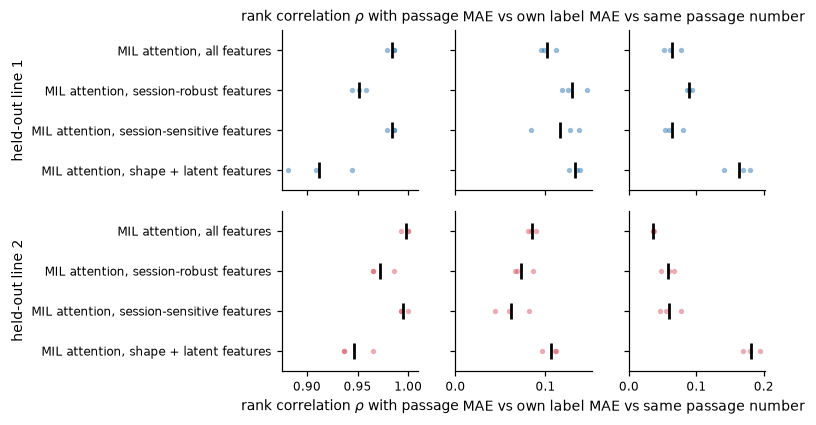

In [12]:
SUBS = [MAIN] + [c for c in ("MIL attention, session-robust features", "MIL attention, session-sensitive features",
                             "MIL attention, shape + latent features") if c in set(per_run.config)]
if len(SUBS) > 1:
    comparison_figure(per_run, SUBS, "M6c_feature_subsets")
    tab = summary.reset_index(); tab = tab[tab.config.isin(SUBS)]
    savetab(tab, "feature_subsets_summary", index=False)
    display(tab.set_index(["held_out_line", "config"])
              [["rho", "mae_own_bin", "mae_own_frac", "mae_same_pass", "s_P15", "late_bias", "s_P18"]]
              .loc[[(h, c) for h in (1, 2) for c in SUBS]].round(3))

In [13]:
# Per-passage means for every configuration (supplementary table)
allpass = gm.groupby(["config", "held_out_line", "passage_raw"])["s_hat"].mean().unstack("passage_raw")
savetab(allpass.round(3), "per_passage_all_configs")
allpass.round(2)

saved thesis_tables/chapter4/per_passage_all_configs.csv


passage_raw                                                4     5     6   \
config                                    held_out_line                     
MIL attention, all features               1              0.00  0.13  0.14   
                                          2              0.01  0.01  0.11   
MIL attention, latent only                1              0.23  0.26  0.26   
                                          2              0.25  0.33  0.22   
MIL attention, manual only                1              0.00  0.13  0.15   
                                          2              0.00  0.00  0.11   
MIL attention, session-robust features    1              0.01  0.15  0.19   
                                          2              0.02  0.01  0.11   
MIL attention, session-sensitive features 1              0.01  0.17  0.14   
                                          2              0.00  0.01  0.11   
MIL attention, shape + latent features    1              0.12  0.19  0.16   
                                          2              0.03  0.08  0.17   
MIL mean pooling, all features            1              0.00  0.13  0.13   
                                          2              0.01  0.00  0.11   
Ridge, bag mean                           1              0.03  0.08  0.22   
                                          2              0.01  0.08  0.07   
Ridge, bag mean + SD                      1              0.03  0.10  0.24   
                                          2              0.05  0.06  0.08   

passage_raw                                                7     8     9   \
config                                    held_out_line                     
MIL attention, all features               1              0.24  0.37  0.47   
                                          2              0.26  0.32  0.36   
MIL attention, latent only                1              0.29  0.71  0.56   
                                          2              0.22  0.36  0.34   
MIL attention, manual only                1              0.22  0.30  0.45   
                                          2              0.26  0.36  0.36   
MIL attention, session-robust features    1              0.24  0.64  0.40   
                                          2              0.21  0.35  0.33   
MIL attention, session-sensitive features 1              0.23  0.33  0.50   
                                          2              0.25  0.30  0.39   
MIL attention, shape + latent features    1              0.20  0.60  0.56   
                                          2              0.11  0.15  0.19   
MIL mean pooling, all features            1              0.24  0.36  0.44   
                                          2              0.25  0.34  0.36   
Ridge, bag mean                           1              0.42  0.39  0.39   
                                          2              0.17  0.22  0.37   
Ridge, bag mean + SD                      1              0.36  0.40  0.33   
                                          2              0.21  0.24  0.35   

passage_raw                                                10    11    12  \
config                                    held_out_line                     
MIL attention, all features               1              0.46  0.60  0.66   
                                          2              0.48  0.65  0.76   
MIL attention, latent only                1              0.65  0.74  0.62   
                                          2              0.28  0.31  0.58   
MIL attention, manual only                1              0.49  0.60  0.64   
                                          2              0.52  0.69  0.78   
MIL attention, session-robust features    1              0.49  0.57  0.70   
                                          2              0.52  0.57  0.76   
MIL attention, session-sensitive features 1              0.46  0.58  0.65   
                                          2              0.46  0.65  0.

# 6 · Late passages and score quantisation

Two behaviours of the neural model that the group means hide.
(a) Bag scores cluster on exact bin values k/9: the model acts as a bin classifier.
(b) Beyond the training range (line 2, P16–P18) individual wells do not decline gradually: each
well is scored either near 1.0 or near 0.4.

saved thesis_tables/chapter4/score_quantisation.csv
saved thesis_tables/chapter4/late_passage_wells.csv
wells scored within 0.006 of an exact bin value: 59%


saved thesis_figures/chapter4/M8_quantisation_and_late_passage_wells.png/.pdf


config
MIL attention, all features       0.171
MIL attention, latent only        0.104
MIL attention, manual only        0.223
MIL mean pooling, all features    0.179
Ridge, bag mean                   0.103
Ridge, bag mean + SD              0.106
Name: interior bag scores within 0.006 of k/9 (chance = 0.10), dtype: float64

,mean,sd,min,max,wells > 0.9,wells < 0.5,wells
passage_raw,,,,,,,
13,0.857,0.055,0.748,0.889,0,0,6
14,0.923,0.094,0.767,1.000,3,0,6
15,1.000,0.000,1.000,1.000,5,0,5
16,0.844,0.230,0.393,1.000,3,1,6
17,0.724,0.264,0.367,0.993,2,2,6
18,0.446,0.005,0.444,0.456,0,6,6


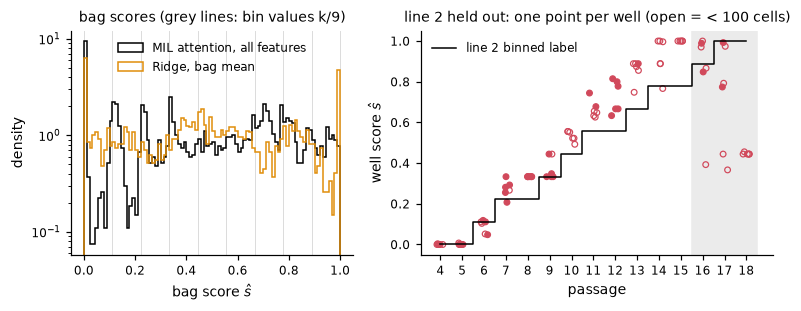

In [14]:
def snapped(s, tol=0.05, k=N_BINS - 1):
    q = np.asarray(s) * k
    return np.abs(q - np.round(q)) < tol

q = pred[pred.family.isin(["main", "baseline"])].copy()
q = q[(q.s_hat > 0.03) & (q.s_hat < 0.97)]              # interior only: ridge is clipped to [0, 1]
q["on_bin"] = snapped(q.s_hat)
quant = q.groupby("config")["on_bin"].mean().rename("interior bag scores within 0.006 of k/9 (chance = 0.10)")
savetab(quant.reset_index(), "score_quantisation", index=False)

fw = REVIEW / "task4" / "well_scores.csv"
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.9), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
bins = np.linspace(0, 1, 91)
for c, col in ((MAIN, "k"), ("Ridge, bag mean", "#e08e0b")):
    if c in set(pred.config):
        ax.hist(pred[pred.config == c].s_hat, bins=bins, histtype="step", color=col, lw=1, density=True, label=c)
for k in range(N_BINS): ax.axvline(k / (N_BINS - 1), color="0.85", lw=0.6, zorder=0)
ax.set_xlabel(r"bag score $\hat{s}$"); ax.set_ylabel("density"); ax.set_yscale("log"); ax.legend(loc="upper center")
ax.set_title("bag scores (grey lines: bin values k/9)")
if fw.exists():
    w = pd.read_csv(fw); ax = axes[1]
    w2 = w[w.cell_line == 2]
    rng = np.random.default_rng(0)
    ax.scatter(w2.passage_raw + rng.uniform(-0.18, 0.18, len(w2)), w2.s_hat_mean, s=14,
               c=np.where(w2.flagged, "none", C_LINE[2]), edgecolors=C_LINE[2], lw=0.8)
    ax.plot(range(4, 19), s_bin(2, np.arange(4, 19)), color="k", lw=1, drawstyle="steps-mid", label="line 2 binned label")
    ax.axvspan(15.5, 18.5, color="0.92", zorder=0)
    ax.set_xticks(range(4, 19)); ax.set_xlabel("passage"); ax.set_ylabel(r"well score $\hat{s}$")
    ax.set_title("line 2 held out: one point per well (open = < 100 cells)"); ax.legend(loc="upper left")
    late = (w2[w2.passage_raw >= 13].groupby("passage_raw")["s_hat_mean"]
              .agg(["mean", "std", "min", "max", lambda x: (x > 0.9).sum(), lambda x: (x < 0.5).sum(), "size"]))
    late.columns = ["mean", "sd", "min", "max", "wells > 0.9", "wells < 0.5", "wells"]
    savetab(late.round(3), "late_passage_wells")
    print(f"wells scored within 0.006 of an exact bin value: {snapped(w.s_hat_mean).mean():.0%}")
fig.tight_layout(); savefig(fig, "M8_quantisation_and_late_passage_wells")
display(quant.round(3)); display(late.round(3) if fw.exists() else None)

# 7 · Confound diagnostics

Both lines were passaged and imaged on the same days, each on its own plate. Session effects are
therefore shared between lines at a given passage, while line-specific biology is not.

**7a. Shared per-passage component.** For each feature the group medians of each line (P4–P15) were
detrended with a quadratic in passage; `resid_r` is the correlation between the two lines'
residuals at matched passage (n = 12), with a permutation p-value.

saved thesis_figures/chapter4/C1_shared_passage_component.png/.pdf
saved thesis_tables/chapter4/shared_component_by_block.csv
48 of 58 features have a positive residual correlation


,n,median_r,n_sig_quadratic,n_sig_linear,n_sig_cubic,median_trend,n_session_robust
block,,,,,,,
intensity,10,0.44,1,2,0,0.35,5
latent,16,0.16,2,1,3,0.22,13
ratio,5,0.53,2,3,2,0.71,1
shape,8,0.48,4,4,4,0.87,4
texture-distribution,19,0.66,15,12,12,0.29,2
all,58,0.46,24,22,21,0.41,25


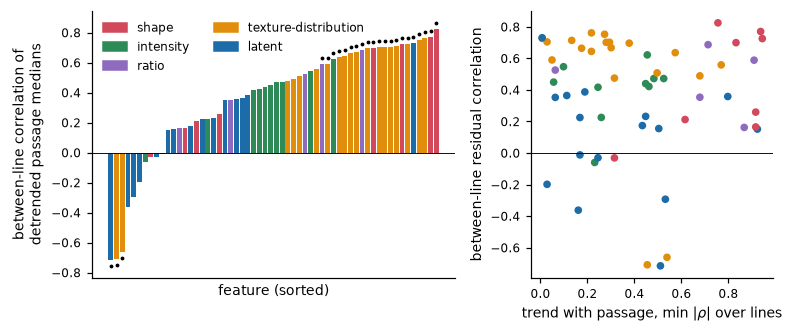

In [15]:
sc = pd.read_csv(REVIEW / "task4" / "session_component.csv").sort_values("resid_r").reset_index(drop=True)
sc["trend"] = sc[["trend_rho_L1", "trend_rho_L2"]].abs().min(axis=1)
sc["shared"] = (sc[["resid_r", "lin_r", "cub_r"]].abs().max(axis=1) >= 0.5) | (sc[["perm_p", "lin_p", "cub_p"]].min(axis=1) <= 0.05)

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.1), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ax.bar(range(len(sc)), sc.resid_r, color=sc.block.map(C_BLOCK), width=0.85)
sig = sc.perm_p < 0.05
ax.plot(np.where(sig)[0], np.where(sc.resid_r[sig] > 0, sc.resid_r[sig] + 0.04, sc.resid_r[sig] - 0.04), "k.", ms=3)
ax.axhline(0, color="k", lw=0.6); ax.set_xlabel("feature (sorted)"); ax.set_xticks([])
ax.set_ylabel("between-line correlation of\ndetrended passage medians")
ax.legend(handles=[mpl.patches.Patch(color=v, label=k) for k, v in C_BLOCK.items()], loc="upper left", ncol=2)
ax = axes[1]
ax.scatter(sc.trend, sc.resid_r, c=sc.block.map(C_BLOCK), s=16)
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel(r"trend with passage, min $|\rho|$ over lines"); ax.set_ylabel("between-line residual correlation")
fig.tight_layout(); savefig(fig, "C1_shared_passage_component")

block = sc.groupby("block").agg(n=("resid_r", "size"), median_r=("resid_r", "median"),
        n_sig_quadratic=("perm_p", lambda x: (x < .05).sum()), n_sig_linear=("lin_p", lambda x: (x < .05).sum()),
        n_sig_cubic=("cub_p", lambda x: (x < .05).sum()), median_trend=("trend", "median"),
        n_session_robust=("shared", lambda x: (~x).sum()))
block.loc["all"] = [len(sc), sc.resid_r.median(), (sc.perm_p < .05).sum(), (sc.lin_p < .05).sum(),
                    (sc.cub_p < .05).sum(), sc.trend.median(), (~sc.shared).sum()]
savetab(block.round(3), "shared_component_by_block")
print(f"{(sc.resid_r > 0).sum()} of {len(sc)} features have a positive residual correlation")
block.round(2)

**7b. Plate layout, between-line contrast, density and row position.**

saved thesis_tables/chapter4/plate_layout_columns.csv


saved thesis_figures/chapter4/C2_layout_contrast_density_row.png/.pdf


passage_raw,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
cell_line,,,,,,,,,,,,,,,
1,3.0,4.0,2.0,3.0,4.0,5.0,6.0,7.0,2.0,3.0,4.0,5.0,NaN,NaN,NaN
2,3.0,4.0,2.0,3.0,4.0,6.0,7.0,8.0,2.0,3.0,4.0,5.0,6.0,2.0,3.0
same_column,True,True,True,True,True,False,False,False,True,True,True,True,False,False,False


,passage,norm,proj,norm_low,norm_high,proj_low,proj_high
0,4,1.93,0.45,1.54,2.84,-0.10,1.19
1,5,2.37,-0.96,2.19,3.23,-1.48,-0.37
2,6,1.62,0.30,1.01,3.18,-0.53,1.57
3,7,1.25,0.17,1.07,2.11,-0.48,0.74
4,8,1.62,0.06,1.26,2.31,-0.62,0.72
5,9,5.77,-2.53,2.51,7.42,-4.56,1.07
6,10,2.91,2.05,2.09,3.88,0.67,2.97
7,11,1.63,0.11,1.57,2.84,-0.96,0.76
8,12,1.96,1.15,1.73,2.43,0.65,1.64
9,13,1.50,0.53,1.20,2.15,0.15,1.09


,within_r,within_r_low,within_r_high,within_rho,within_rho_low,within_rho_high
0,0.014,-0.147,0.143,0.01,-0.147,0.154


,cell_line,row_r,row_p,row_rho,row_rho_p
0,1,-0.4235,0.0002,-0.4898,0.0000
1,2,-0.1219,0.2552,-0.2254,0.0337


wells with < 100 cells: 62% | wells: 160 | cells: 16505


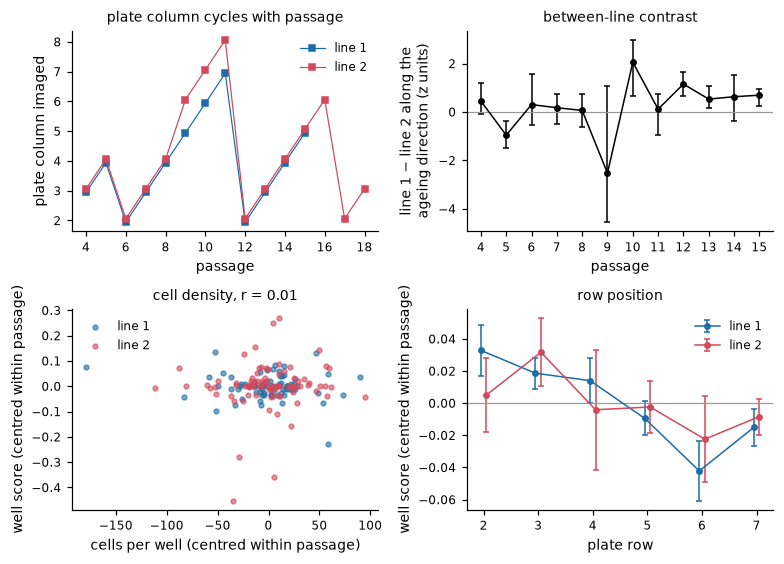

In [16]:
pl = pd.read_csv(REVIEW / "task4" / "plate_layout.csv")
colcols = [c for c in pl.columns if c not in ("cell_line", "passage_raw")]
pl["column"] = pl[colcols].to_numpy().argmax(axis=1); pl["column"] = [int(colcols[i]) for i in pl["column"]]
pl["n_wells"] = pl[colcols].sum(axis=1)
lay = pl.pivot(index="passage_raw", columns="cell_line", values="column")
lay["same_column"] = lay[1] == lay[2]
savetab(lay, "plate_layout_columns")

lc = pd.read_csv(REVIEW / "task4" / "line_contrast.csv")
w  = pd.read_csv(REVIEW / "task4" / "well_scores.csv")
grp = w.groupby(["cell_line", "passage_raw"])
w["score_c"] = w.s_hat_mean - grp.s_hat_mean.transform("mean")
w["n_c"]     = w.n_cells - grp.n_cells.transform("mean")

fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.2))
ax = axes[0, 0]
for l in (1, 2):
    d = pl[pl.cell_line == l]
    ax.plot(d.passage_raw, d.column + (l - 1.5) * 0.12, "s-", ms=4, lw=0.8, color=C_LINE[l], label=f"line {l}")
ax.set_xlabel("passage"); ax.set_ylabel("plate column imaged"); ax.set_xticks(range(4, 19, 2)); ax.legend()
ax.set_title("plate column cycles with passage")
ax = axes[0, 1]
ax.errorbar(lc.passage, lc.proj, yerr=[lc.proj - lc.proj_low, lc.proj_high - lc.proj], fmt="o-", ms=3.5, lw=1, color="k", capsize=2)
ax.axhline(0, color="0.6", lw=0.8); ax.set_xticks(lc.passage); ax.set_xlabel("passage")
ax.set_ylabel("line 1 − line 2 along the\nageing direction (z units)"); ax.set_title("between-line contrast")
ax = axes[1, 0]
for l in (1, 2):
    d = w[w.cell_line == l]; ax.scatter(d.n_c, d.score_c, s=10, color=C_LINE[l], alpha=0.6, label=f"line {l}")
r = np.corrcoef(w.n_c, w.score_c)[0, 1]
ax.set_xlabel("cells per well (centred within passage)"); ax.set_ylabel("well score (centred within passage)")
ax.set_title(f"cell density, r = {r:.2f}"); ax.legend()
ax = axes[1, 1]
for l in (1, 2):
    d = w[w.cell_line == l].groupby("row").score_c.agg(["mean", "sem"])
    ax.errorbar(d.index + (l - 1.5) * 0.1, d["mean"], yerr=d["sem"], fmt="o-", ms=3.5, lw=1, color=C_LINE[l], capsize=2, label=f"line {l}")
ax.axhline(0, color="0.6", lw=0.8); ax.set_xlabel("plate row"); ax.set_ylabel("well score (centred within passage)")
ax.set_title("row position"); ax.legend()
fig.tight_layout(); savefig(fig, "C2_layout_contrast_density_row")

dens = pd.read_csv(REVIEW / "task4" / "density_summary.csv"); rowe = pd.read_csv(REVIEW / "task4" / "row_effect.csv")
display(lay.T); display(lc.round(2)); display(dens.round(3)); display(rowe.round(4))
print("wells with < 100 cells:", f"{w.flagged.mean():.0%}", "| wells:", len(w), "| cells:", w.n_cells.sum())

# 8 · Attention and feature attribution

**8a. How concentrated is the attention?** Normalised entropy of 1 and a top-decile mass of 0.10
correspond to uniform weights, i.e. mean pooling.

> These files come from the earlier LOCO runs (`loco_binned_HO_L*`), whose checkpoints were selected
> on the held-out line. Re-run `explain.py` on the Task 1 checkpoints and point `LEGACY` at the new
> outputs before using the numbers in the thesis. The conclusions are not expected to change, because
> mean pooling reproduces the attention model in section 4.

saved thesis_figures/chapter4/B1_attention_concentration.png/.pdf
saved thesis_tables/chapter4/attention_concentration_summary.csv


,norm_entropy,top10pct_mass,eff_cell_frac
min,0.987,0.144,0.943
median,0.992,0.158,0.965
max,0.994,0.179,0.974


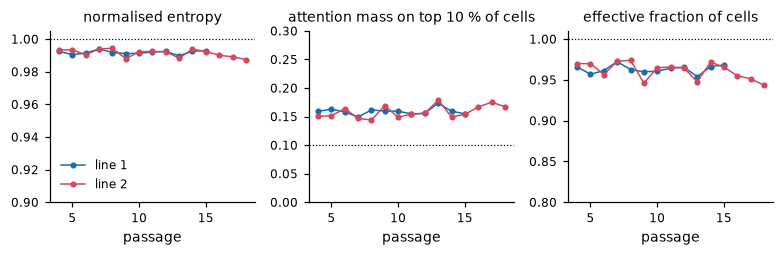

In [17]:
fa = LEGACY / "attention_concentration.csv"
if fa.exists():
    ac = pd.read_csv(fa)
    fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.4))
    for ax, (col, lab, ref) in zip(axes, [("norm_entropy", "normalised entropy", 1.0),
                                          ("top10pct_mass", "attention mass on top 10 % of cells", 0.10),
                                          ("eff_cell_frac", "effective fraction of cells", 1.0)]):
        for l in (1, 2):
            d = ac[ac.line == l]; ax.plot(d.passage, d[col], "o-", ms=3, lw=1, color=C_LINE[l], label=f"line {l}")
        ax.axhline(ref, color="k", ls=":", lw=0.8); ax.set_xlabel("passage"); ax.set_title(lab)
    axes[0].set_ylim(0.9, 1.005); axes[1].set_ylim(0, 0.3); axes[2].set_ylim(0.8, 1.01); axes[0].legend()
    fig.tight_layout(); savefig(fig, "B1_attention_concentration")
    att = ac[["norm_entropy", "top10pct_mass", "eff_cell_frac"]].agg(["min", "median", "max"]).round(3)
    savetab(att, "attention_concentration_summary"); display(att)

In [18]:
# Relative attention weight per cell (1 = uniform), from the per-cell mean attention tables
rel = []
for ho in (1, 2):
    f = LEGACY / f"loco_binned_HO_L{ho}_attention.csv"
    if f.exists():
        a = pd.read_csv(f)
        a["rel"] = a.mean_attention / a.groupby(["cell_line", "passage"]).mean_attention.transform("mean")
        rel.append(a.assign(model=f"held-out line {ho}"))
if rel:
    rel = pd.concat(rel)
    qs = rel.groupby("model")["rel"].quantile([0.01, 0.05, 0.5, 0.95, 0.99]).unstack().round(2)
    savetab(qs, "relative_attention_quantiles"); display(qs)

saved thesis_tables/chapter4/relative_attention_quantiles.csv


,0.01,0.05,0.50,0.95,0.99
model,,,,,
held-out line 1,0.54,0.63,0.96,1.52,1.86
held-out line 2,0.58,0.66,0.96,1.47,1.76


**8b. Are the same features used in both directions?** If the model had learned line-independent
ageing markers, the feature ranking of the model trained on line 1 should agree with the ranking of
the model trained on line 2. Shown for the linear baseline (coefficients) and for the neural model
(integrated gradients, block-normalised).

saved thesis_figures/chapter4/B2_feature_use_between_directions.png/.pdf
saved thesis_tables/chapter4/feature_agreement.csv


,rho_magnitude,rho_signed,rho_signed_between_seeds_same_direction
ridge coefficient,0.26,0.03,0.51
"integrated gradients, mean |IG|",0.21,0.21,NaN


ridge coefficient


,trained on line 1,trained on line 2
0,skew_20per_10,skew_40per_6
1,var_40per_11,var_20per_1
2,rawIntDen_14,skew_4
3,var_20per_14,Perimeter
4,ratio3,skew_20per_10
5,rawIntDen_13,ratio5
6,Area,kurt_40per_2
7,mean_1,kurt_20per_4
8,rawIntDen_12,skew_40per_3
9,kurt_40per_2,ratio8


integrated gradients, mean |IG|


,trained on line 1,trained on line 2
0,ratio5,Circularity
1,Area,mean_1
2,ratio4,mean_3
3,MinAxisLength,ratio5
4,Perimeter,ratio4
5,rawIntDen_12,latent_3
6,latent_15,ratio8
7,MaxAxisLength,skew_20per_10
8,var_40per_2,kurt_20per_4
9,ratio6,ratio3


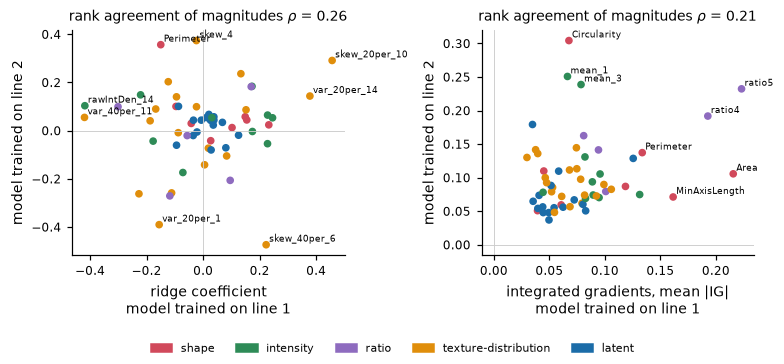

In [19]:
def block_of(f):
    if f.startswith("latent"): return "latent"
    if f in ("Area", "Perimeter", "Eccentricity", "Circularity", "MinAxisLength", "MaxAxisLength", "AspectRatio", "Extent"): return "shape"
    if f.startswith("ratio"): return "ratio"
    if f.startswith(("mean", "rawIntDen")): return "intensity"
    return "texture-distribution"

panels = []
fr = REVIEW / "task3" / "ridge_coefficients.csv"
if fr.exists():
    rc = pd.read_csv(fr); rc = rc[~rc.run_id.str.contains("meanstd")]
    rc["train_line"] = 3 - rc.run_id.str.extract(r"HO_L(\d)")[0].astype(int)
    m = rc.groupby(["feature", "train_line"]).coefficient.mean().unstack()
    panels.append(("ridge coefficient", m))
    seed_r = rc.pivot(index="feature", columns="run_id", values="coefficient").corr(method="spearman")
fi = [LEGACY / f"loco_binned_HO_L{h}_importance_normalised.csv" for h in (1, 2)]
if all(f.exists() for f in fi):
    ig = pd.concat([pd.read_csv(f).assign(train_line=3 - h) for f, h in zip(fi, (1, 2))])
    panels.append(("integrated gradients, mean |IG|", ig.pivot(index="feature", columns="train_line", values="global_mean_abs_ig")))

if panels:
    fig, axes = plt.subplots(1, len(panels), figsize=(3.6 * len(panels), 3.3), squeeze=False)
    agree = {}
    for ax, (name, m) in zip(axes[0], panels):
        m = m.dropna(); blk = m.index.map(block_of)
        ax.scatter(m[1], m[2], c=blk.map(C_BLOCK), s=16)
        rho = spearmanr(m[1].abs(), m[2].abs())[0]
        agree[name] = {"rho_magnitude": rho, "rho_signed": spearmanr(m[1], m[2])[0]}
        top = (m.abs().rank(ascending=False).min(axis=1)).nsmallest(8).index
        for f in top: ax.annotate(f, (m.loc[f, 1], m.loc[f, 2]), fontsize=6, xytext=(2, 2), textcoords="offset points")
        ax.axhline(0, color="0.8", lw=0.6); ax.axvline(0, color="0.8", lw=0.6)
        ax.set_xlabel(f"{name}\nmodel trained on line 1"); ax.set_ylabel("model trained on line 2")
        ax.set_title(rf"rank agreement of magnitudes $\rho$ = {rho:.2f}")
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    fig.legend(handles=[mpl.patches.Patch(color=v, label=k) for k, v in C_BLOCK.items()], ncol=5, loc="lower center", fontsize=7)
    savefig(fig, "B2_feature_use_between_directions")
    agree = pd.DataFrame(agree).T
    if fr.exists():                                  # stability of ridge coefficients across seeds, same direction
        within = [seed_r.loc[a, b] for a in seed_r for b in seed_r if a < b and a.split("_seed")[0] == b.split("_seed")[0]]
        agree.loc["ridge coefficient", "rho_signed_between_seeds_same_direction"] = np.mean(within)
    savetab(agree, "feature_agreement"); display(agree.round(2))
    for name, m in panels:
        t = pd.concat([m[1].abs().nlargest(10).index.to_series().reset_index(drop=True).rename("trained on line 1"),
                       m[2].abs().nlargest(10).index.to_series().reset_index(drop=True).rename("trained on line 2")], axis=1)
        print(name); display(t)

**8c. (optional) What distinguishes high- from low-attention cells?** Needs the processed feature
matrices. Compares the top and bottom attention decile within each passage group. With attention this
close to uniform the effect sizes matter more than the p-values: 16 505 cells make everything
"significant".

In [20]:
fm, fl = PROC / "features_manual.npy", PROC / "features_latent.npy"
fa1 = LEGACY / "loco_binned_HO_L2_attention.csv"
if fm.exists() and fa1.exists():
    import pickle
    X = np.hstack([np.load(fm), np.load(fl)])
    cols = pickle.load(open(PROC / "manual_cols.pkl", "rb")) + pickle.load(open(PROC / "latent_cols.pkl", "rb"))
    a = pd.read_csv(fa1)
    assert len(a) == len(X), "attention table and feature matrix are not row-aligned"
    Z = (X - X.mean(0)) / X.std(0)
    dec = a.groupby(["cell_line", "passage"]).mean_attention.transform(lambda v: pd.qcut(v.rank(method="first"), 10, labels=False))
    hi, lo = (dec == 9).to_numpy(), (dec == 0).to_numpy()
    eff = pd.DataFrame({"feature": cols, "d": Z[hi].mean(0) - Z[lo].mean(0),
                        "p": [mannwhitneyu(Z[hi, j], Z[lo, j]).pvalue for j in range(Z.shape[1])]})
    eff["block"] = eff.feature.map(block_of); eff = eff.sort_values("d")
    fig, ax = plt.subplots(figsize=(7.2, 2.8))
    ax.bar(range(len(eff)), eff.d, color=eff.block.map(C_BLOCK)); ax.axhline(0, color="k", lw=0.6)
    ax.set_xticks(range(len(eff))); ax.set_xticklabels(eff.feature, rotation=90, fontsize=5)
    ax.set_ylabel("top − bottom attention decile\n(z units)")
    fig.tight_layout(); savefig(fig, "B3_attention_decile_contrast"); savetab(eff, "attention_decile_contrast", index=False)
else:
    print("skipped: processed features or attention table not found")

skipped: processed features or attention table not found


## Files written

In [21]:
for d in (FIG_DIR, TAB_DIR):
    print(d); [print("  ", p.name) for p in sorted(d.iterdir()) if p.suffix in (".png", ".csv")]

thesis_figures/chapter4
   B1_attention_concentration.png
   B2_feature_use_between_directions.png
   B3_attention_decile_contrast.png
   C1_shared_passage_component.png
   C2_layout_contrast_density_row.png
   D1_design_schematic.png
   D2_cell_counts.png
   D3_label_grid.png
   D4_pca.png
   D4_umap.png
   D5_correlation_and_variance_partition.png
   D6a_trend_agreement.png
   D6b_univariate_trends.png
   M1_heldout_trajectories.png
   M2_alignment_error.png
   M6a_baselines.png
   M6b_linear_vs_neural_trajectories.png
   M6c_feature_subsets.png
   M7_training_curves.png
   M8_quantisation_and_late_passage_wells.png
thesis_tables/chapter4
   alignment_main.csv
   attention_concentration_summary.csv
   attention_decile_contrast.csv
   baselines_summary.csv
   dataset_counts.csv
   feature_agreement.csv
   feature_subsets_summary.csv
   heldout_trajectory_main.csv
   label_grid.csv
   late_passage_wells.csv
   metrics_per_run.csv
   metrics_summary.csv
   pc_variance_by_factor.csv
   p